# Thực nghiệm 01 — So sánh 4 mô hình trên tập A

So sánh Logistic Regression, Random Forest, SVM và XGBoost trên 36 đặc trưng
gốc của tập A trong `development.csv`. Lượt này dùng lại cấu hình từ lần
so sánh A với A+B để làm mốc cho các lượt thử tham số tiếp theo.

Cả bốn mô hình dùng chung 5 fold theo Stratified K-Fold
(`shuffle=True`, `random_state=42`). Chỉ số so sánh là Macro-F1 trung bình
qua 5 fold.

## 1. Cấu hình và tham số

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

cwd = Path.cwd().resolve()
project_dir = next(
    (
        folder
        for folder in (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
        if (folder / "feature_b" / "common.py").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Hãy mở repo sgu-MAYHOC trong VS Code rồi chạy lại.")

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = project_dir / "experiments" / "2026-11-13_4MoHinh_TapA_Thuong"

N_FOLDS = 5
SEED = 42

configs = {
    "Logistic Regression": (
        LogisticRegression,
        {"C": 0.1, "class_weight": "balanced", "solver": "lbfgs", "max_iter": 3000},
        True,
    ),
    "Random Forest": (
        RandomForestClassifier,
        {
            "n_estimators": 200, "max_depth": None, "min_samples_leaf": 1,
            "class_weight": "balanced", "random_state": SEED, "n_jobs": 1,
        },
        False,
    ),
    "SVM": (
        SVC,
        {"kernel": "rbf", "C": 10, "gamma": 0.01, "class_weight": "balanced"},
        True,
    ),
    "XGBoost": (
        XGBClassifier,
        {
            "n_estimators": 150, "max_depth": 6, "learning_rate": 0.1,
            "objective": "multi:softprob", "num_class": 3,
            "eval_metric": "mlogloss", "tree_method": "hist",
            "random_state": SEED, "n_jobs": 1,
        },
        False,
    ),
}

config_table = pd.DataFrame([
    {
        "Mô hình": name,
        "Tham số thiết lập": ", ".join(f"{key}={value!r}" for key, value in params.items()),
        "Chuẩn hóa cột số": "Có" if scale_numeric else "Không",
    }
    for name, (_, params, scale_numeric) in configs.items()
])
display(config_table)

,Mô hình,Tham số thiết lập,Chuẩn hóa cột số
0,Logistic Regression,"C=0.1, class_weight='balanced', solver='lbfgs'...",Có
1,Random Forest,"n_estimators=200, max_depth=None, min_samples_...",Không
2,SVM,"kernel='rbf', C=10, gamma=0.01, class_weight='...",Có
3,XGBoost,"n_estimators=150, max_depth=6, learning_rate=0...",Không


## 2. Huấn luyện và đánh giá

Mỗi mô hình học trên 4 fold và dự đoán trên fold còn lại. Lặp qua cả 5 fold,
sau đó lấy trung bình Macro-F1 và xếp hạng các mô hình.

In [2]:
X_a, _, y = load_development(data_path)
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows = []
fold_tables = []
parameter_rows = []

for name, (model_class, params, scale_numeric) in configs.items():
    print(f"Đang chạy {name}...")
    model = model_class(**params)
    summary, scores = evaluate(name, model, scale_numeric, "A", X_a, y, folds)
    summary_rows.append(summary)
    fold_tables.append(scores)

    for key, value in model.get_params(deep=False).items():
        parameter_rows.append({
            "Mô hình": name,
            "Tham số": key,
            "Giá trị": repr(value),
        })

results = (
    pd.DataFrame(summary_rows)
    .sort_values("cv_macro_f1", ascending=False)
    .reset_index(drop=True)
)
fold_results = pd.concat(fold_tables, ignore_index=True)
parameters = pd.DataFrame(parameter_rows)

display(results.round(6))
best = results.iloc[0]
print(f"Cao nhất lượt này: {best['model']} ({best['cv_macro_f1']:.6f})")

3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang chạy Logistic Regression...
Đang chạy Random Forest...
Đang chạy SVM...
Đang chạy XGBoost...


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate
0,Logistic Regression,A,36,0.717353,0.733509,0.618898,0.823430
1,Random Forest,A,36,0.716244,0.748461,0.508661,0.877759
2,SVM,A,36,0.715364,0.736148,0.595276,0.832484
3,XGBoost,A,36,0.713649,0.760774,0.434646,0.916808


Cao nhất lượt này: Logistic Regression (0.717353)


## 3. Biểu đồ và lưu kết quả

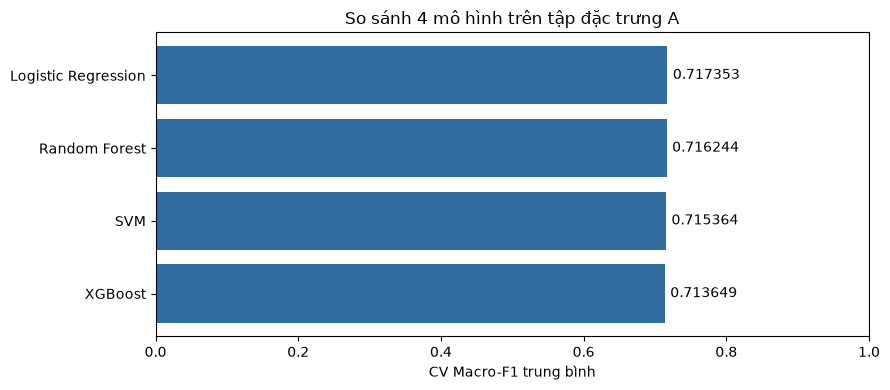

Đã lưu Excel: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-13_4MoHinh_TapA_Thuong\ket_qua.xlsx
Đã lưu ảnh: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-13_4MoHinh_TapA_Thuong\so_sanh_macro_f1.png


In [3]:
output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "ket_qua.xlsx"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Người chạy": "Lê Đỗ Hoà Thương",
    "Tập đặc trưng": "A",
    "Dữ liệu": "data/processed/development.csv",
    "Số mẫu": len(y),
    "Số đặc trưng": X_a.shape[1],
    "Kiểm định chéo": "StratifiedKFold",
    "Số fold": N_FOLDS,
    "Shuffle": True,
    "Random state": SEED,
    "Chỉ số": "CV Macro-F1 trung bình",
}])

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    run_info.to_excel(writer, sheet_name="Cau hinh luot chay", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    parameters.to_excel(writer, sheet_name="Tham so day du", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(results["model"], results["cv_macro_f1"], color="#316C9E")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung bình")
ax.set_title("So sánh 4 mô hình trên tập đặc trưng A")
ax.bar_label(bars, fmt="%.6f", padding=4)
fig.tight_layout()
fig.savefig(image_path, dpi=180)
plt.show()

print(f"Đã lưu Excel: {excel_path}")
print(f"Đã lưu ảnh: {image_path}")

## Nhận xét:
Trong lượt thực nghiệm trên tập A, Logistic Regression có CV Macro-F1 trung bình cao nhất (0,717353), hơn Random Forest (0,716244) khoảng 0,001109. Chênh lệch giữa hai mô hình khá nhỏ. Riêng với lớp Dropout, XGBoost có recall cao nhất (76,08%), còn Logistic Regression đạt 73,35%. Vì vậy, kết quả xếp hạng theo Macro-F1 và kết quả nhận diện riêng lớp Dropout cho thấy hai ưu điểm khác nhau.